# 3. Output Prioritization

Outputs differ in how much a new LTU can help them. Some have a strong signal and little noise, some a weak signal and
much noise, and some no signal at all. Can search give new LTUs to the outputs whose error a new LTU can decrease, and
so learn faster than with uniform parents? This notebook starts with one hidden layer, where every parent is an
output.

**Problem.** `problems.SparseTargetNetwork` with 1 depth of 60 target LTUs, each reading 10 inputs. Each of the 100
outputs reads 6 target LTUs, so each target LTU feeds about 10 outputs. Each output has its own signal multiplier and
noise std. Each takes one of 10 levels evenly spaced from 0 to 1, and the 100 outputs take every pair of levels.

**Baseline.** `algorithms.PruneAndMove` of notebook 2 with 1 depth: 48 LTUs at step 0, at most 96, and a budget of
1200 connections. A new LTU's parent is an output drawn uniformly.

**Proposed.** `algorithms.PrioritizedOutputs`. Lines marked (3) are new:

```
every step
  L_o, M_o   output o's mean |prediction_o - y_o|, with weights that decay with time constants of 10k steps (L,  (3)
             fast) and 80k steps (M, slow): the unit period, and the time that SEARCH takes to replace all LTUs.
  s_o        the standard error of M_o - L_o: the std of |prediction_o - y_o| times the root of the summed       (3)
             squared differences between the normalized fast and slow weights
  P_o        (M_o - L_o) / M_o * L_o   if M_o - L_o > 3 s_o, else 0                                             (3)

NEW LTU u
  parent: an output drawn in proportion to P_o + mean(P), uniformly if all P are 0                               (3)
```

The rule of `../output_prioritization/` also divides P_o by o's new inputs. Here every output reads every LTU, so that
count is the same for all outputs and does not change the draw.

The second figure shows, for each method, where the new LTUs go: the share of them whose parent is in each fifth of
the outputs, ranked by signal-to-noise ratio (signal / noise std).

5 seeds, 1M steps.

In [1]:
import os
os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'
import jax
jax.config.update('jax_platforms', 'cuda')

from phd.sandbox.unit_search.algorithm import algorithms, experiment, problems

assert jax.default_backend() == 'gpu'
%matplotlib inline

In [2]:
signal, noise_std = problems.signal_noise_grid()
problem = problems.SparseTargetNetwork(noise_std=noise_std, signal=signal, depths=1, width=60, output_fan_in=6)
sizes = dict(n_inputs=problem.n_inputs, n_outputs=problem.n_outputs, depths=1, width=48, max_ltus=96, budget=1200)
methods = {'uniform parents (baseline)': algorithms.PruneAndMove(**sizes),
           'prioritized outputs (proposed)': algorithms.PrioritizedOutputs(**sizes)}
rmse, new_parents = experiment.run(methods, problem, steps=1_000_000)

uniform parents (baseline): RMSE over the last 10% 0.602 ; at the end, 96 LTUs and 1095 connections from x and LTUs (57s)


prioritized outputs (proposed): RMSE over the last 10% 0.602 ; at the end, 96 LTUs and 1159 connections from x and LTUs (95s)


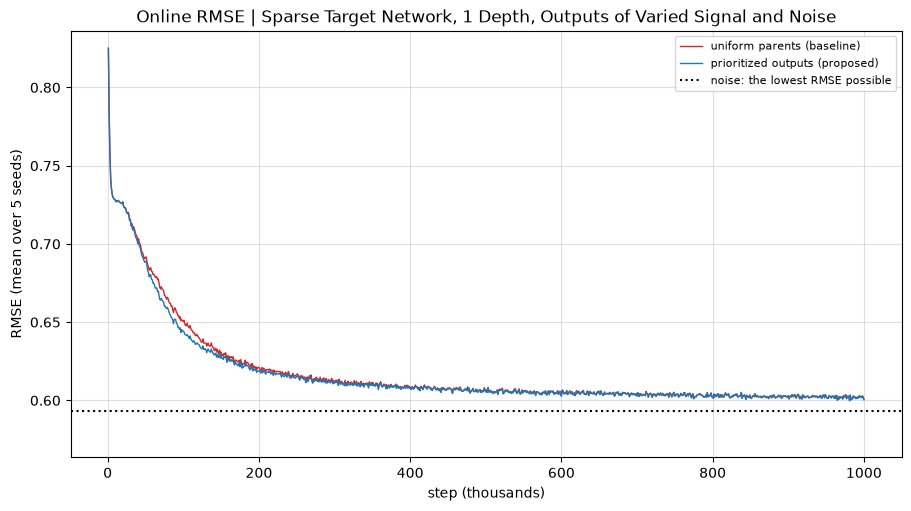

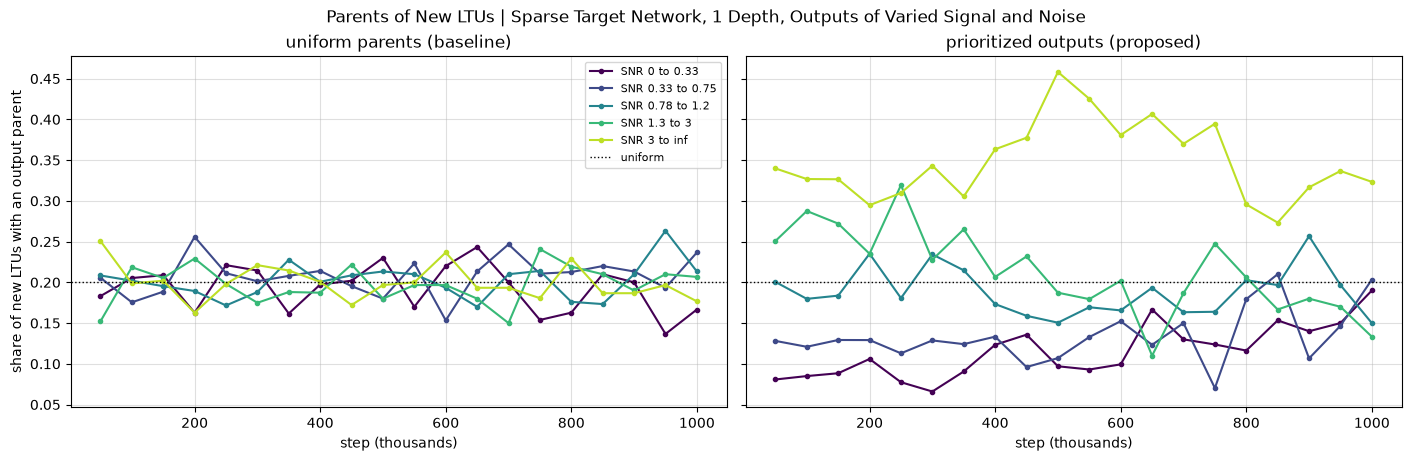

In [3]:
title = 'Sparse Target Network, 1 Depth, Outputs of Varied Signal and Noise'
experiment.plot(rmse, problem, f'Online RMSE | {title}')
experiment.plot_new_parents(new_parents, problem, f'Parents of New LTUs | {title}')